
# US Retail Sales Forecasting

## Project Overview

This project analyzes historical monthly retail sales in the United States and forecasts future sales using time series models.

The objective is to identify sales trends, explore seasonality, and compare different forecasting approaches.

### Planned Models
- Seasonal Naive (Baseline)
- SARIMA
- Prophet
- XGBoost

### Data Source
Federal Reserve Economic Data (FRED)
Series: MRTSSM44000USN

Source: https://fred.stlouisfed.org/series/MRTSSM44000USN

The dataset contains monthly retail sales figures measured in millions of US dollars.

### Tools
Python, Pandas, NumPy, Matplotlib, Scikit-learn, Statsmodels, Prophet, XGBoost.




## 1. Data Loading

The monthly retail sales dataset is retrieved from FRED and loaded into a Pandas DataFrame.

We inspect the dataset structure, date range, and sample records before data preprocessing.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load monthly US retail sales data from FRED
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=MRTSSM44000USN"

df = pd.read_csv(url)

# Convert the date column
df["observation_date"] = pd.to_datetime(
    df["observation_date"]
)

# Inspect dataset
print("Dataset shape:", df.shape)

print("\nDate range:")
print(df["observation_date"].min())
print(df["observation_date"].max())

display(df.head())

print("\nData types:")
df.info()


Dataset shape: (416, 2)

Date range:
1992-01-01 00:00:00
2026-08-01 00:00:00


,observation_date,MRTSSM44000USN
0,1992-01-01,126717
1,1992-02-01,127022
2,1992-03-01,137978
3,1992-04-01,142314
4,1992-05-01,147550



Data types:
<class 'pandas.DataFrame'>
RangeIndex: 416 entries, 0 to 415
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   observation_date  416 non-null    datetime64[us]
 1   MRTSSM44000USN    416 non-null    int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 6.6 KB



## 2. Save Dataset Locally

The original dataset is saved as a CSV file to ensure reproducibility and simplify future analysis.

The source remains publicly available through FRED.


In [2]:

from pathlib import Path

# Create a local data directory
Path("data").mkdir(exist_ok=True)

# Save the original dataset
df.to_csv(
    "data/us_retail_sales.csv",
    index=False
)

print("Dataset saved successfully.")
print("Rows:", len(df))


Dataset saved successfully.
Rows: 416



## 3. Initial Data Quality Check

We examine missing values, duplicate dates, and the statistical summary of retail sales.

This step helps identify potential data quality issues before time series analysis.


In [3]:

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate dates
print("\nDuplicate dates:")
print(df["observation_date"].duplicated().sum())

# Statistical summary
print("\nDescriptive statistics:")
display(df.describe())

# Check date ordering
print("\nDates sorted:",
      df["observation_date"].is_monotonic_increasing)


Missing values:
observation_date    0
MRTSSM44000USN      0
dtype: int64

Duplicate dates:
0

Descriptive statistics:


,observation_date,MRTSSM44000USN
count,416,416.000000
mean,2009-04-16 11:11:32.307692,344221.360577
min,1992-01-01 00:00:00,126717.000000
25%,2000-08-24 06:00:00,238729.250000
50%,2009-04-16 00:00:00,323098.000000
75%,2017-12-08 18:00:00,415669.500000
max,2026-08-01 00:00:00,694088.000000
std,NaN,137621.292305



Dates sorted: True



## 4. Data Cleaning & Time Series Preparation

We prepare the monthly retail sales data for time series analysis by validating the date column, converting sales values to numeric format, and checking for missing monthly observations.

The cleaned dataset is indexed by date to support forecasting and seasonal analysis.


In [4]:

# Rename columns for readability
df = df.rename(columns={
    "observation_date": "Date",
    "MRTSSM44000USN": "Sales"
})

# Convert columns to appropriate types
df["Date"] = pd.to_datetime(df["Date"])
df["Sales"] = pd.to_numeric(
    df["Sales"], errors="coerce"
)

# Sort observations chronologically
df = df.sort_values("Date").copy()

# Set monthly date index
df = df.set_index("Date").asfreq("MS")

# Check missing monthly observations
print("Missing sales values:", df["Sales"].isna().sum())

# Inspect cleaned dataset
print("Dataset shape:", df.shape)
display(df.head())

# Check frequency
print("Frequency:", df.index.freqstr)


Missing sales values: 0
Dataset shape: (416, 1)


,Sales
Date,
1992-01-01,126717
1992-02-01,127022
1992-03-01,137978
1992-04-01,142314
1992-05-01,147550


Frequency: MS



## 5. Exploratory Data Analysis

### 5.1 Historical Sales Trend

We visualize the historical monthly retail sales data to identify long-term trends, fluctuations, and potential structural changes.

The analysis uses the original non-seasonally adjusted sales values.


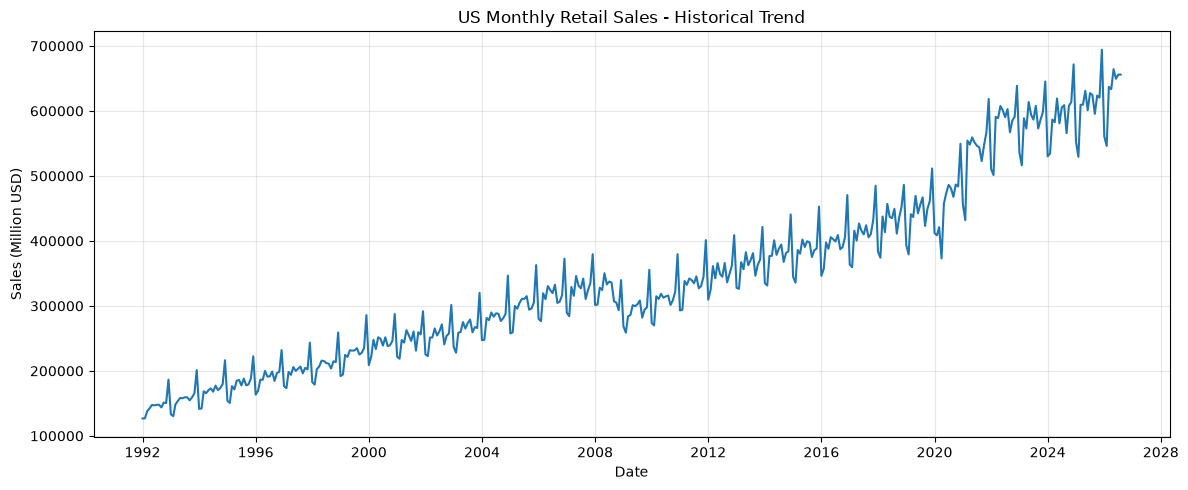

In [5]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    df.index,
    df["Sales"],
    linewidth=1.5
)

plt.title("US Monthly Retail Sales - Historical Trend")
plt.xlabel("Date")
plt.ylabel("Sales (Million USD)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### 5.2 Monthly Seasonality

We examine average retail sales by calendar month to explore recurring seasonal patterns.

Monthly averages are descriptive and may also reflect the long-term sales trend.


Month
1     306715.77
2     303022.46
3     346129.29
4     339617.34
5     360429.09
6     351135.23
7     352749.06
8     359517.43
9     328611.82
10    340407.53
11    346883.18
12    396451.53
Name: Sales, dtype: float64

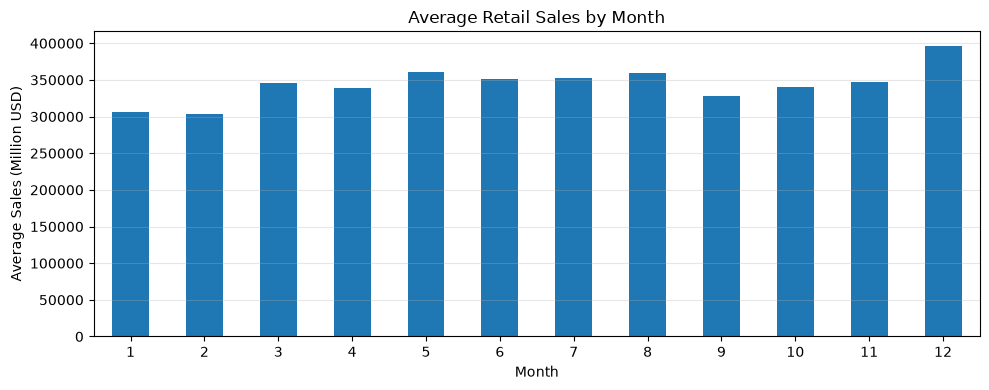

In [6]:

# Create a copy for exploratory analysis
eda_df = df.copy()

# Extract month and year
eda_df["Month"] = eda_df.index.month
eda_df["Year"] = eda_df.index.year

# Calculate average sales by month
monthly_avg = eda_df.groupby("Month")["Sales"].mean()

display(monthly_avg.round(2))

# Visualize monthly patterns
plt.figure(figsize=(10, 4))

monthly_avg.plot(kind="bar")

plt.title("Average Retail Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales (Million USD)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



### 5.3 Year-over-Year Sales Growth

We calculate the percentage change in retail sales compared with the same month of the previous year.

This helps reveal changes in annual sales growth while reducing the influence of recurring seasonal fluctuations.


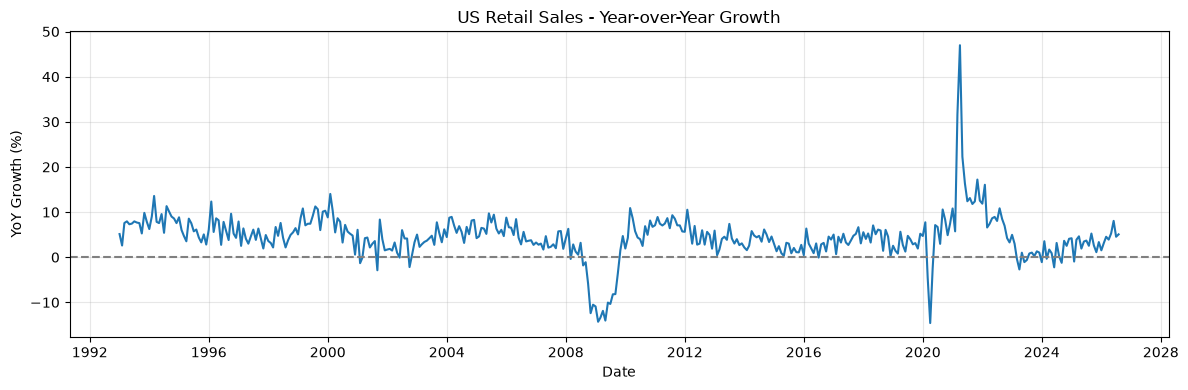

Latest available YoY growth:


,Sales,YoY_Growth
Date,,
2026-04-01,633425,3.90
2026-05-01,664214,5.26
2026-06-01,649437,8.06
2026-07-01,655940,4.53
2026-08-01,655885,5.06


In [7]:

# Calculate year-over-year growth
eda_df["YoY_Growth"] = (
    eda_df["Sales"].pct_change(
        periods=12,
        fill_method=None
    ) * 100
)

# Plot annual growth
plt.figure(figsize=(12, 4))

plt.plot(
    eda_df.index,
    eda_df["YoY_Growth"]
)

plt.axhline(0, linestyle="--", color="gray")

plt.title("US Retail Sales - Year-over-Year Growth")
plt.xlabel("Date")
plt.ylabel("YoY Growth (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Latest available YoY growth:")
display(eda_df[["Sales", "YoY_Growth"]].tail(5).round(2))



**Insight:** Negative year-over-year growth indicates a decline in retail sales compared with the same month of the previous year, not negative sales revenue.

The series shows substantial contractions around the 2008–2009 financial crisis and the onset of the COVID-19 pandemic in 2020, followed by a sharp rebound in 2021.

These structural changes may affect forecasting performance and should be considered during model evaluation.



## 6. Seasonal Decomposition

We decompose the monthly US retail sales series into trend, seasonal, and residual components using an additive model.

The goal is to examine long-term sales movements and recurring annual patterns before developing forecasting models.

A seasonal period of 12 is used because the dataset contains monthly observations.


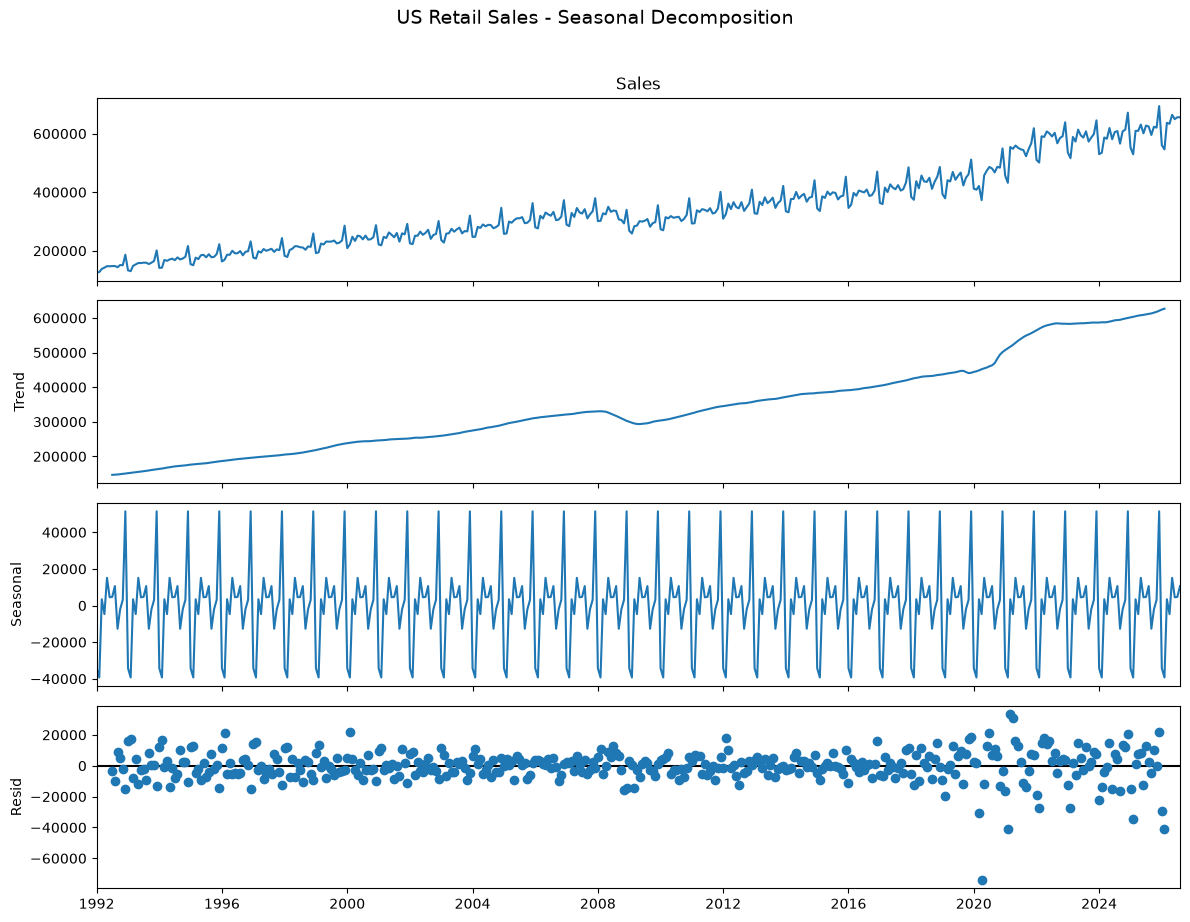

In [8]:

from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# Prepare the time series
sales_series = df["Sales"].dropna()

# Perform additive seasonal decomposition
decomposition = seasonal_decompose(
    sales_series,
    model="additive",
    period=12
)

# Visualize components
fig = decomposition.plot()
fig.set_size_inches(12, 9)

fig.suptitle(
    "US Retail Sales - Seasonal Decomposition",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()



### Decomposition Insights

The decomposition helps visualize the underlying trend, recurring seasonal patterns, and unexplained variations in monthly retail sales.

An additive decomposition provides an initial descriptive view of the series. The suitability of additive versus multiplicative seasonality should be assessed before final model selection.

The decomposition is used for exploratory analysis, not as a direct measure of forecasting accuracy.



## 7. Train/Test Split

The dataset is divided chronologically into training and testing periods.

The final 12 months are reserved as a holdout test set, while earlier observations are used for model training.

This approach preserves temporal order and allows evaluation of 12-month-ahead forecasting performance.

Model selection and hyperparameter tuning will be performed using only the training period.


Training observations: 404
Testing observations: 12

Training period:
1992-01-01 00:00:00 to 2025-08-01 00:00:00

Testing period:
2025-09-01 00:00:00 to 2026-08-01 00:00:00


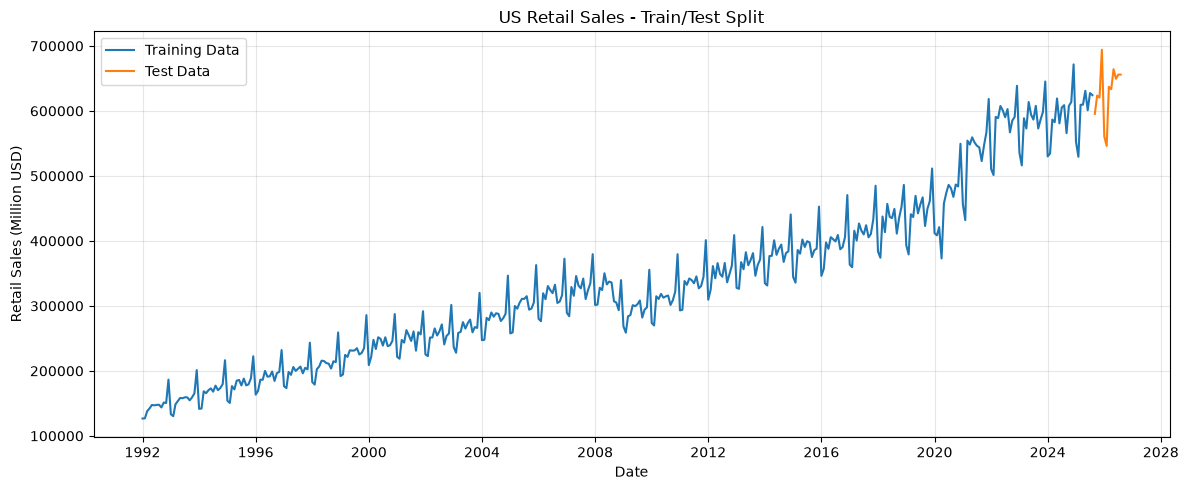

In [9]:

# Define the forecasting horizon
forecast_horizon = 12

# Verify sufficient history and no missing values
assert sales_series.notna().all(), "Missing sales values found."
assert len(sales_series) > 36, "Insufficient history."

# Chronological split
train = sales_series.iloc[:-forecast_horizon]
test = sales_series.iloc[-forecast_horizon:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

# Visualize training and test periods
plt.figure(figsize=(12, 5))

plt.plot(
    train.index,
    train,
    label="Training Data"
)

plt.plot(
    test.index,
    test,
    label="Test Data"
)

plt.title("US Retail Sales - Train/Test Split")
plt.xlabel("Date")
plt.ylabel("Retail Sales (Million USD)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Train/Test Split Insights

A chronological split ensures that observations from the future are not used to train models intended to predict earlier periods.
.
The final 12 months are held out for evaluation, providing a realistic test of forecasting performance over a one-year horizon.

The same test period will be used to compare all forecasting models.



## 8. Seasonal Naive Baseline

A Seasonal Naive model is used as the baseline forecasting method.

For monthly data, the model assumes that sales in each future month will equal sales from the same month of the previous year.

This provides a simple benchmark for evaluating more advanced forecasting models.

The forecasting horizon is 12 months.
m


Seasonal Naive Results
MAE: 24,433.92
RMSE: 26,804.73
MAPE: 3.85%


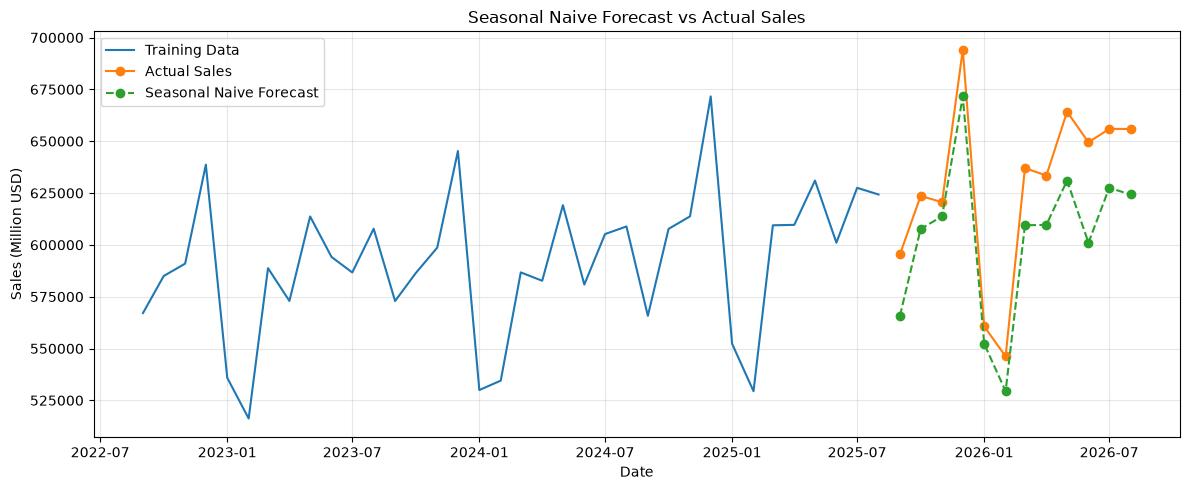

In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# Forecast the next 12 months using last year's values
naive_forecast = pd.Series(
    train.iloc[-12:].to_numpy(),
    index=test.index,
    name="Seasonal Naive"
)

# Evaluation metrics
naive_mae = mean_absolute_error(test, naive_forecast)
naive_rmse = np.sqrt(
    mean_squared_error(test, naive_forecast)
)

naive_mape = (
    np.mean(
        np.abs(
            (test.to_numpy() - naive_forecast.to_numpy())
            / test.to_numpy()
        )
    ) * 100
)

print("Seasonal Naive Results")
print(f"MAE: {naive_mae:,.2f}")
print(f"RMSE: {naive_rmse:,.2f}")
print(f"MAPE: {naive_mape:.2f}%")

# Visualize the forecast
plt.figure(figsize=(12, 5))

plt.plot(
    train.index[-36:],
    train.iloc[-36:],
    label="Training Data"
)

plt.plot(
    test.index,
    test,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    naive_forecast.index,
    naive_forecast,
    label="Seasonal Naive Forecast",
    linestyle="--",
    marker="o"
)

plt.title("Seasonal Naive Forecast vs Actual Sales")
plt.xlabel("Date")
plt.ylabel("Sales (Million USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Seasonal Naive Baseline Insights

The Seasonal Naive model uses the previous year's monthly sales values as forecasts for the corresponding months in the test period.

Its performance serves as a benchmark for SARIMA, Prophet, and XGBoost.

More advanced models should demonstrate meaningful improvements over this simple approach to justify their additional complexity.



## 9. SARIMA Forecasting

A Seasonal Autoregressive Integrated Moving Average (SARIMA) model is trained to capture temporal dependencies and annual seasonality in monthly retail sales.

The model is fitted only on the training period and generates forecasts for the next 12 months.

The initial model configuration is evaluated before further tuning.


In [11]:

from statsmodels.tsa.statespace.sarimax import SARIMAX

# Initialize SARIMA model
sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Train model
sarima_fit = sarima_model.fit(disp=False)

# Forecast the test period
sarima_forecast = sarima_fit.forecast(
    steps=len(test)
)

sarima_forecast.index = test.index

# Evaluate model
sarima_mae = mean_absolute_error(
    test, sarima_forecast
)

sarima_rmse = np.sqrt(
    mean_squared_error(test, sarima_forecast)
)

sarima_mape = np.mean(
    np.abs(
        (test.to_numpy() - sarima_forecast.to_numpy())
        / test.to_numpy()
    )
) * 100

print("SARIMA Results")
print(f"MAE: {sarima_mae:,.2f}")
print(f"RMSE: {sarima_rmse:,.2f}")
print(f"MAPE: {sarima_mape:.2f}%")

print("\nModel AIC:", round(sarima_fit.aic, 2))


SARIMA Results
MAE: 12,230.51
RMSE: 13,907.69
MAPE: 1.91%

Model AIC: 8085.43


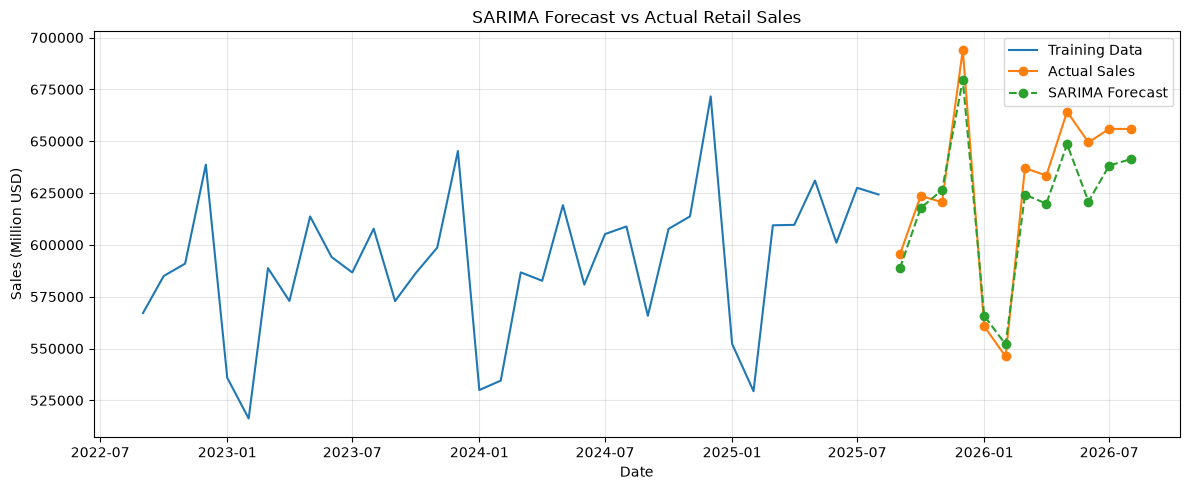

In [12]:

plt.figure(figsize=(12, 5))

plt.plot(
    train.index[-36:],
    train.iloc[-36:],
    label="Training Data"
)

plt.plot(
    test.index,
    test,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    sarima_forecast.index,
    sarima_forecast,
    label="SARIMA Forecast",
    linestyle="--",
    marker="o"
)

plt.title("SARIMA Forecast vs Actual Retail Sales")
plt.xlabel("Date")
plt.ylabel("Sales (Million USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### SARIMA Model Insights

The SARIMA model outperformed the Seasonal Naive baseline across all three evaluation metrics.

- MAE decreased from 24,433.92 to 12,230.51 million USD.
- RMSE decreased from 26,804.73 to 13,907.69 million USD.
- MAPE improved from 3.85% to 1.91%, representing approximately a 50% reduction in percentage error.

The results suggest that SARIMA captures temporal dependencies and seasonal sales patterns more effectively than the baseline on this 12-month holdout period.

Further evaluation using rolling-origin backtesting is required to assess model stability across different historical periods.




## 10. Prophet Forecasting

Prophet is used to model the historical retail sales trend and recurring yearly seasonal patterns.

The model is trained only on the training dataset and generates forecasts for the 12-month holdout period.

Forecast accuracy is measured using MAE, RMSE, and MAPE.


In [16]:

from prophet import Prophet

# Prepare training data for Prophet
prophet_train = train.reset_index()
prophet_train.columns = ["ds", "y"]

# Initialize model
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

# Train model
prophet_model.fit(prophet_train)

# Forecast the existing test dates
future = pd.DataFrame({"ds": test.index})

prophet_predictions = prophet_model.predict(future)

prophet_forecast = pd.Series(
    prophet_predictions["yhat"].to_numpy(),
    index=test.index,
    name="Prophet"
)

# Evaluation
prophet_mae = mean_absolute_error(
    test, prophet_forecast
)

prophet_rmse = np.sqrt(
    mean_squared_error(test, prophet_forecast)
)

prophet_mape = np.mean(
    np.abs(
        (test.to_numpy() - prophet_forecast.to_numpy())
        / test.to_numpy()
    )
) * 100

print("Prophet Results")
print(f"MAE: {prophet_mae:,.2f}")
print(f"RMSE: {prophet_rmse:,.2f}")
print(f"MAPE: {prophet_mape:.2f}%")


09:33:16 - cmdstanpy - INFO - Chain [1] start processing
09:33:17 - cmdstanpy - INFO - Chain [1] done processing


Prophet Results
MAE: 23,820.48
RMSE: 29,988.41
MAPE: 4.00%


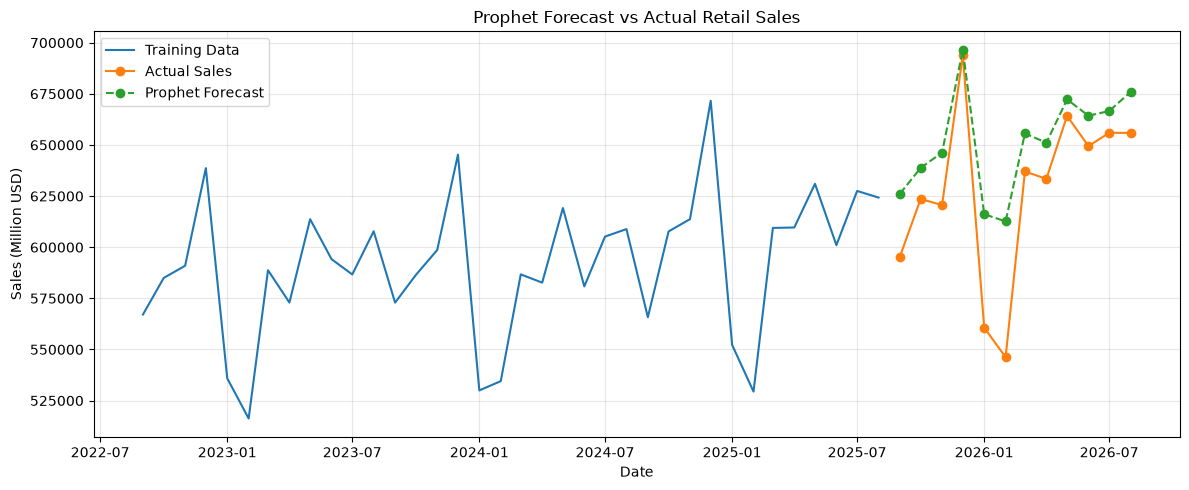

In [17]:

plt.figure(figsize=(12, 5))

plt.plot(
    train.iloc[-36:],
    label="Training Data"
)

plt.plot(
    test,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    prophet_forecast,
    label="Prophet Forecast",
    marker="o",
    linestyle="--"
)

plt.title("Prophet Forecast vs Actual Retail Sales")
plt.xlabel("Date")
plt.ylabel("Sales (Million USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Prophet Model Insights

Prophet achieved a MAPE of 4.00%, compared with 1.91% for SARIMA and 3.85% for the Seasonal Naive baseline.

Although Prophet captured some seasonal patterns, it struggled to predict the sharp decline in retail sales at the beginning of 2026.

SARIMA demonstrated stronger performance across all three evaluation metrics on the current holdout period.

Further rolling-origin backtesting is needed to evaluate model consistency across different periods.



## 11. XGBoost Forecasting

XGBoost is a gradient boosting algorithm adapted for time series forecasting through feature engineering.

We create lagged sales features and calendar-based predictors to capture historical dependencies and seasonal patterns.

Recursive forecasting is used to generate 12-month-ahead predictions without accessing actual sales values from the test period.


In [18]:

from xgboost import XGBRegressor

# Create lag-based features
def create_features(series):
    data = pd.DataFrame({"Sales": series})

    for lag in [1, 2, 3, 12]:
        data[f"lag_{lag}"] = data["Sales"].shift(lag)

    data["month"] = data.index.month
    data["year"] = data.index.year

    return data.dropna()

# Use training data only
train_features = create_features(train)

X_train_xgb = train_features.drop(columns="Sales")
y_train_xgb = train_features["Sales"]

# Initialize XGBoost
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train model
xgb_model.fit(X_train_xgb, y_train_xgb)

print("XGBoost training completed.")
print("Training samples:", len(X_train_xgb))


XGBoost training completed.
Training samples: 392


In [19]:

# Recursive 12-month forecasting
history = list(train.to_numpy())
predictions = []

for date in test.index:
    features = pd.DataFrame([{
        "lag_1": history[-1],
        "lag_2": history[-2],
        "lag_3": history[-3],
        "lag_12": history[-12],
        "month": date.month,
        "year": date.year
    }])

    forecast_value = float(
        xgb_model.predict(features)[0]
    )

    predictions.append(forecast_value)
    history.append(forecast_value)

xgb_forecast = pd.Series(
    predictions,
    index=test.index,
    name="XGBoost"
)

# Evaluate predictions
xgb_mae = mean_absolute_error(test, xgb_forecast)

xgb_rmse = np.sqrt(
    mean_squared_error(test, xgb_forecast)
)

xgb_mape = np.mean(
    np.abs(
        (test.to_numpy() - xgb_forecast.to_numpy())
        / test.to_numpy()
    )
) * 100

print("XGBoost Results")
print(f"MAE: {xgb_mae:,.2f}")
print(f"RMSE: {xgb_rmse:,.2f}")
print(f"MAPE: {xgb_mape:.2f}%")


XGBoost Results
MAE: 17,355.63
RMSE: 21,572.28
MAPE: 2.67%


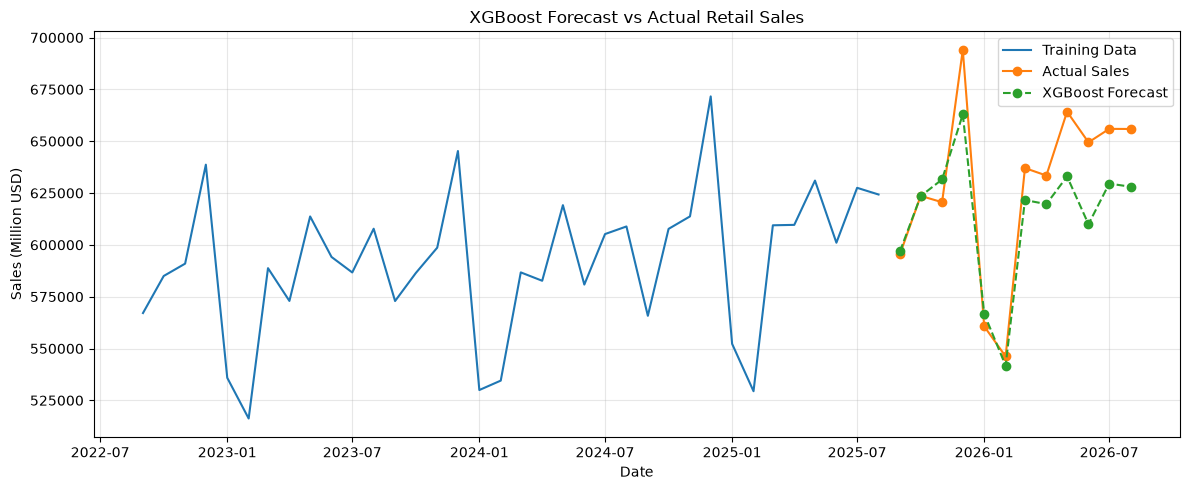

In [20]:

plt.figure(figsize=(12, 5))

plt.plot(
    train.iloc[-36:],
    label="Training Data"
)

plt.plot(
    test,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    xgb_forecast,
    label="XGBoost Forecast",
    marker="o",
    linestyle="--"
)

plt.title("XGBoost Forecast vs Actual Retail Sales")
plt.xlabel("Date")
plt.ylabel("Sales (Million USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



## 12. Model Performance Comparison

We compare four forecasting approaches using the same 12-month holdout period.

The evaluation metrics include Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE).

Lower values indicate better forecasting accuracy.

The holdout comparison is descriptive. Rolling-origin backtesting on the training period will provide additional evidence of model stability.


In [21]:

# Compare forecasting models
comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "SARIMA",
        "Prophet",
        "XGBoost"
    ],
    "MAE": [
        naive_mae,
        sarima_mae,
        prophet_mae,
        xgb_mae
    ],
    "RMSE": [
        naive_rmse,
        sarima_rmse,
        prophet_rmse,
        xgb_rmse
    ],
    "MAPE (%)": [
        naive_mape,
        sarima_mape,
        prophet_mape,
        xgb_mape
    ]
})

comparison = comparison.sort_values(
    "MAPE (%)"
).reset_index(drop=True)

display(
    comparison.style
    .format({
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "MAPE (%)": "{:.2f}%"
    })
    .background_gradient(
        cmap="Greens",
        subset=["MAPE (%)"],
        vmin=0,
        vmax=6
    )
)


,Model,MAE,RMSE,MAPE (%)
0,SARIMA,"12,230.51","13,907.69",1.91%
1,XGBoost,"17,355.63","21,572.28",2.67%
2,Seasonal Naive,"24,433.92","26,804.73",3.85%
3,Prophet,"23,820.48","29,988.41",4.00%


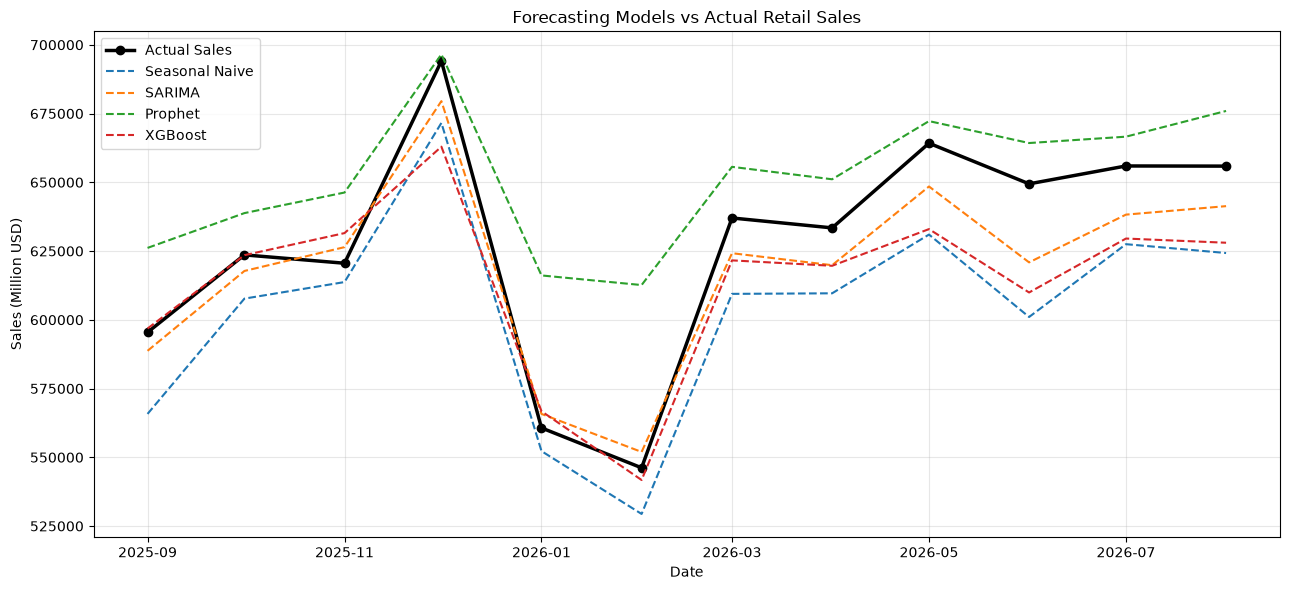

In [22]:

plt.figure(figsize=(13, 6))

plt.plot(
    test.index, test,
    label="Actual Sales",
    color="black",
    linewidth=2.5,
    marker="o"
)

forecasts = {
    "Seasonal Naive": naive_forecast,
    "SARIMA": sarima_forecast,
    "Prophet": prophet_forecast,
    "XGBoost": xgb_forecast
}

for name, forecast in forecasts.items():
    plt.plot(
        forecast.index,
        forecast,
        label=name,
        linestyle="--"
    )

plt.title("Forecasting Models vs Actual Retail Sales")
plt.xlabel("Date")
plt.ylabel("Sales (Million USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Model Comparison Insights

SARIMA achieved the lowest forecasting errors on the 12-month holdout set, with a MAPE of 1.91%.

XGBoost ranked second with a MAPE of 2.67%, followed by Seasonal Naive at 3.85% and Prophet at 4.00%.

SARIMA reduced MAPE by approximately 50% compared with the Seasonal Naive baseline.

These findings apply to the evaluated holdout period and do not establish that SARIMA will always outperform the other models.



## 13. Rolling-Origin Backtesting

We evaluate forecasting performance across three historical validation windows using expanding training periods.

Each model generates a 12-month forecast without accessing the actual values in its validation window.

All backtesting folds are contained within the original training dataset, keeping the final holdout period separate.

The objective is to assess model stability and support model selection using MAE, RMSE, and MAPE.


In [23]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet
from xgboost import XGBRegressor

import pandas as pd
import numpy as np

# Forecasting settings
horizon = 12
n_folds = 3

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE": np.mean(
            np.abs((actual - predicted) / actual)
        ) * 100
    }


def xgb_recursive_forecast(training, dates):
    feature_data = create_features(training)

    X = feature_data.drop(columns="Sales")
    y = feature_data["Sales"]

    model = XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X, y)

    history = list(training.to_numpy())
    predictions = []

    for date in dates:
        features = pd.DataFrame([{
            "lag_1": history[-1],
            "lag_2": history[-2],
            "lag_3": history[-3],
            "lag_12": history[-12],
            "month": date.month,
            "year": date.year
        }])

        prediction = float(model.predict(features)[0])
        predictions.append(prediction)
        history.append(prediction)

    return np.array(predictions)


backtest_results = []

for fold in range(n_folds):
    remaining = (n_folds - fold) * horizon

    fold_train = train.iloc[:-remaining]

    fold_valid = train.iloc[
        -remaining : -remaining + horizon
    ] if remaining > horizon else train.iloc[-horizon:]

    print(f"Running fold {fold + 1}/{n_folds}")

    # 1. Seasonal Naive
    naive_pred = fold_train.iloc[-12:].to_numpy()

    # 2. SARIMA
    sarima = SARIMAX(
        fold_train,
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    sarima_fit_cv = sarima.fit(disp=False)
    sarima_pred = sarima_fit_cv.forecast(
        steps=horizon
    ).to_numpy()

    # 3. Prophet
    prophet_data = fold_train.reset_index()
    prophet_data.columns = ["ds", "y"]

    prophet_cv = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False
    )

    prophet_cv.fit(prophet_data)

    prophet_pred = prophet_cv.predict(
        pd.DataFrame({"ds": fold_valid.index})
    )["yhat"].to_numpy()

    # 4. XGBoost
    xgb_pred_cv = xgb_recursive_forecast(
        fold_train,
        fold_valid.index
    )

    predictions = {
        "Seasonal Naive": naive_pred,
        "SARIMA": sarima_pred,
        "Prophet": prophet_pred,
        "XGBoost": xgb_pred_cv
    }

    for name, pred in predictions.items():
        metrics = calculate_metrics(fold_valid, pred)

        backtest_results.append({
            "Fold": fold + 1,
            "Model": name,
            **metrics
        })

backtest_df = pd.DataFrame(backtest_results)

display(backtest_df.round(2))


Running fold 1/3


09:41:02 - cmdstanpy - INFO - Chain [1] start processing
09:41:02 - cmdstanpy - INFO - Chain [1] done processing


Running fold 2/3


09:41:04 - cmdstanpy - INFO - Chain [1] start processing
09:41:04 - cmdstanpy - INFO - Chain [1] done processing


Running fold 3/3


09:41:06 - cmdstanpy - INFO - Chain [1] start processing
09:41:06 - cmdstanpy - INFO - Chain [1] done processing


,Fold,Model,MAE,RMSE,MAPE
0,1,Seasonal Naive,17170.83,21674.07,2.99
1,1,SARIMA,37778.20,40763.71,6.48
2,1,Prophet,23868.75,26010.55,4.04
3,1,XGBoost,14280.32,16089.52,2.45
4,2,Seasonal Naive,7984.00,9818.66,1.38
5,2,SARIMA,17716.27,21250.95,3.02
6,2,Prophet,18212.34,22679.70,3.19
7,2,XGBoost,9402.66,11194.01,1.60
8,3,Seasonal Naive,18057.00,19309.44,2.96
9,3,SARIMA,8701.15,10120.71,1.44



### 13.1 Backtesting Results

The models are compared using average forecasting errors across the three validation folds.

We also examine the variability of MAPE to understand whether forecasting performance is consistent across historical periods.

These results are used to support model selection.


In [24]:

# Summarize backtesting performance
backtest_summary = (
    backtest_df.groupby("Model")
    .agg(
        MAE=("MAE", "mean"),
        RMSE=("RMSE", "mean"),
        MAPE=("MAPE", "mean"),
        MAPE_Std=("MAPE", "std")
    )
    .sort_values("MAPE")
)

display(
    backtest_summary.style
    .format("{:,.2f}")
    .background_gradient(
        cmap="Blues",
        subset=["MAPE"]
    )
)

print(
    "Lowest average MAPE:",
    backtest_summary.index[0]
)


,MAE,RMSE,MAPE,MAPE_Std
Model,,,,
XGBoost,"14,160.14","15,735.20",2.38,0.74
Seasonal Naive,"14,403.94","16,934.06",2.44,0.92
SARIMA,"21,398.54","24,045.12",3.65,2.58
Prophet,"23,650.72","27,460.98",4.06,0.88


Lowest average MAPE: XGBoost


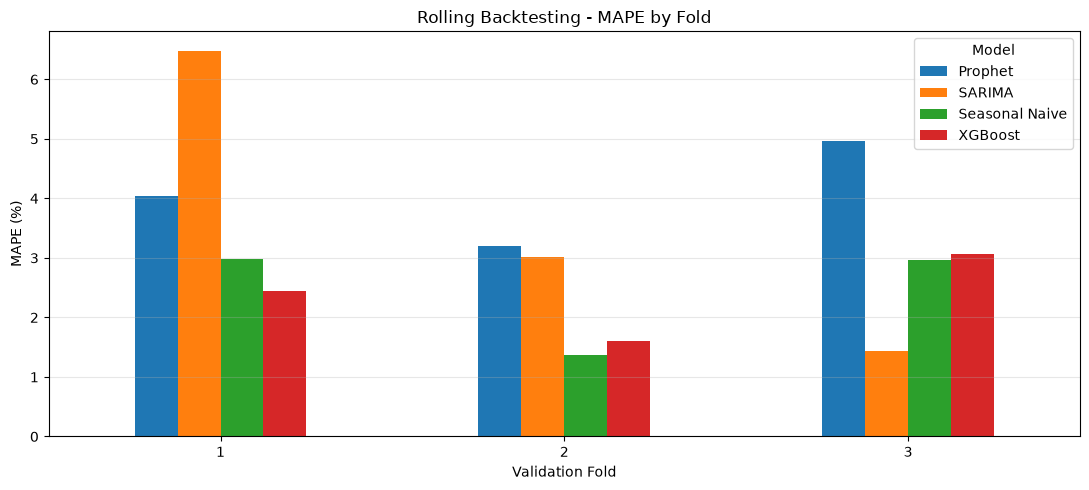

In [25]:

# Visualize MAPE across validation folds
pivot_mape = backtest_df.pivot(
    index="Fold",
    columns="Model",
    values="MAPE"
)

ax = pivot_mape.plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_title("Rolling Backtesting - MAPE by Fold")
ax.set_xlabel("Validation Fold")
ax.set_ylabel("MAPE (%)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



## 14. Final Model Selection

Four forecasting approaches were evaluated:

- Seasonal Naive
- SARIMA
- Prophet
- XGBoost

SARIMA achieved the lowest error on the previously examined 12-month holdout period, with a MAPE of 1.91%.

The preferred model is determined using average rolling-origin validation performance, considering accuracy, stability, and model complexity.

The holdout metrics are reported separately from backtesting results. No additional parameter tuning is performed on the holdout period.


In [26]:

# Select preferred model using backtesting results
best_model = backtest_summary.index[0]

print("Preferred model based on backtesting:")
print(best_model)

print("\nBacktesting metrics:")
display(backtest_summary.loc[[best_model]].round(2))

print("\nPreviously evaluated holdout metrics:")
display(
    comparison.loc[
        comparison["Model"] == best_model
    ].round(2)
)


Preferred model based on backtesting:
XGBoost

Backtesting metrics:


,MAE,RMSE,MAPE,MAPE_Std
Model,,,,
XGBoost,14160.14,15735.2,2.38,0.74



Previously evaluated holdout metrics:


,Model,MAE,RMSE,MAPE (%)
1,XGBoost,17355.63,21572.28,2.67



## 15. Export Results

The final model comparison, rolling backtesting metrics, and visualizations are exported to support reproducibility and documentation.

The exported files will be included in the GitHub repository.


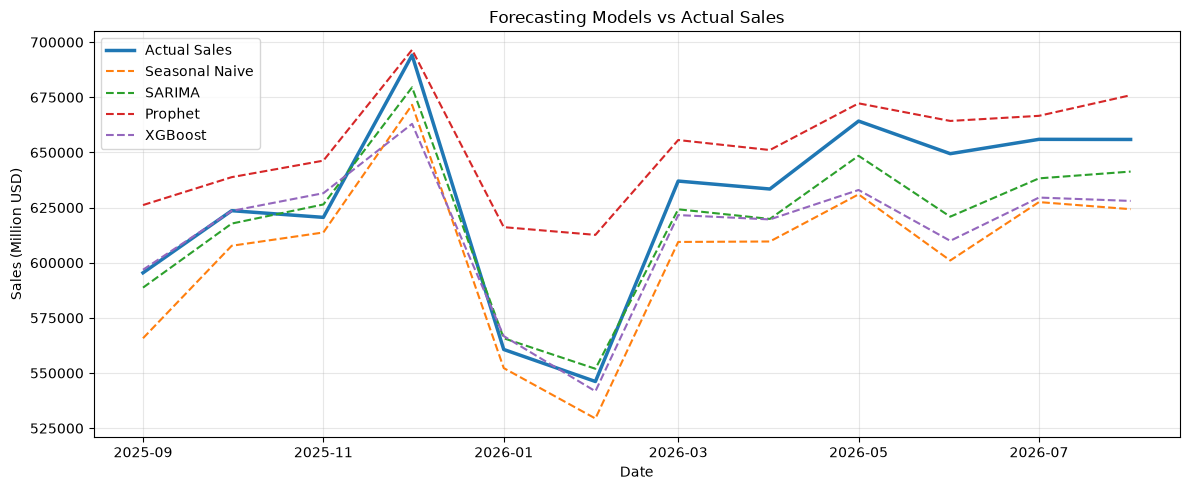

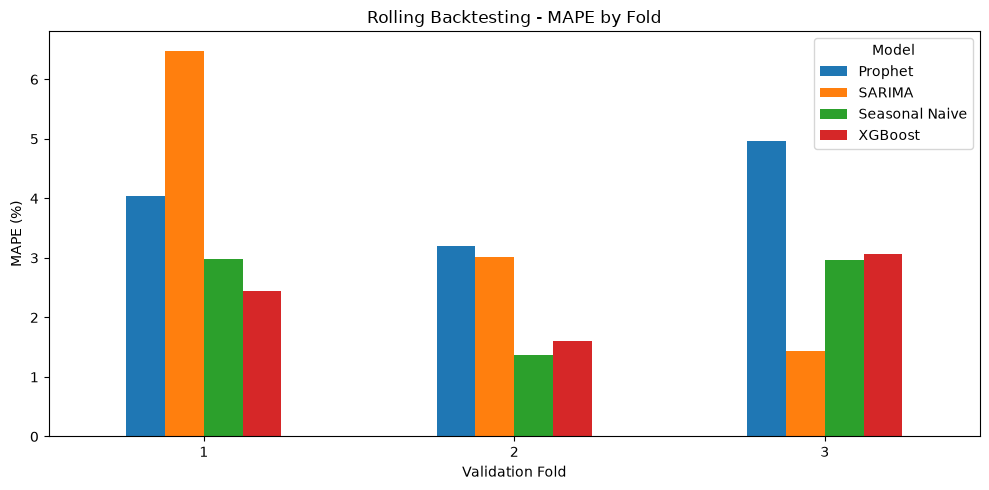

Results and images saved successfully.


In [27]:

from pathlib import Path

# Create output directories
Path("images").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

# Save model evaluation tables
comparison.to_csv(
    "results/model_comparison.csv",
    index=False
)

backtest_df.to_csv(
    "results/backtesting_folds.csv",
    index=False
)

backtest_summary.to_csv(
    "results/backtesting_summary.csv"
)

# Save forecast comparison chart
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    test.index,
    test,
    label="Actual Sales",
    linewidth=2.5
)

for name, forecast in forecasts.items():
    ax.plot(
        forecast.index,
        forecast,
        label=name,
        linestyle="--"
    )

ax.set_title("Forecasting Models vs Actual Sales")
ax.set_xlabel("Date")
ax.set_ylabel("Sales (Million USD)")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(
    "images/forecast_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Save backtesting comparison chart
ax = pivot_mape.plot(
    kind="bar",
    figsize=(10, 5)
)

ax.set_title("Rolling Backtesting - MAPE by Fold")
ax.set_xlabel("Validation Fold")
ax.set_ylabel("MAPE (%)")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

plt.savefig(
    "images/backtesting_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Results and images saved successfully.")



## 16. Conclusion & Future Improvements

This project evaluated four forecasting approaches for monthly US retail sales: Seasonal Naive, SARIMA, Prophet, and XGBoost.

### Key Findings

- SARIMA achieved the lowest MAPE (1.91%) on the 12-month holdout period.
- XGBoost achieved the lowest average MAPE (2.38%) across three rolling-origin validation folds.
- Seasonal Naive remained competitive, achieving a backtesting MAPE of 2.44%.
- SARIMA showed greater variability across validation periods.

### Model Selection

XGBoost was selected as the preferred model based on its average rolling-origin validation performance.

However, its improvement over Seasonal Naive was small. Additional validation would be necessary before claiming a consistent performance advantage.

### Limitations

- Only three rolling validation windows were evaluated.
- The data represents nominal retail sales and is not inflation-adjusted.
- External economic indicators were not included.
- Forecasting accuracy may change during economic disruptions.
- The initial holdout results were examined before completing backtesting.

### Future Improvements

- Expand rolling-origin validation.
- Optimize hyperparameters using training-only validation.
- Incorporate economic indicators.
- Evaluate prediction intervals.
- Deploy an interactive forecasting dashboard.
